# Backtest modeli pogodowych dla Polski

**Cel:** dla każdego punktu siatki 0.25° nad Polską i każdego horyzontu prognozy wskazać model,
który najdokładniej prognozuje temperaturę 2 m (sekcje 1–9) i ciśnienie (sekcja 10). Macierz `best_model[lead, lat, lon]` odpowiada na
pytanie „jaki model pogodowy jest najlepszy w mojej miejscowości”. Wyniki trafiają do
`predictions/backtest/model_map_{zmienna}.zarr`, z którego serwis będzie brał prognozę dla danego punktu.

| Rola | Źródło | Ścieżka w buckecie S3 `openmeteo.s3.amazonaws.com` |
|---|---|---|
| ground truth | reanaliza ERA5 (ECMWF / Copernicus) | `data/copernicus_era5/temperature_2m/chunk_{i}.om` |
| prognozy | 7 globalnych modeli deterministycznych | `data_run/{model}/{YYYY}/{MM}/{DD}/{HHMM}Z/temperature_2m.om` |

Bucket S3 jest publiczny, bez rejestracji i bez kluczy API. Pliki `.om` czytamy po zakresach bajtów
(HTTP Range), więc z ~550 MB pliku GFS pobieramy ~2.5 MB, które przypadają na Polskę.

## Modele

Siedem globalnych modeli deterministycznych, każdy z 4 runami na dobę (00/06/12/18 UTC). Krok czasu
i horyzont odczytaliśmy z `time` w plikach (runy z 2026-09-20), a rozdzielczość z `crs_wkt` i wymiarów siatki.

| model (id w buckecie S3) | operator | typ | siatka | runy 00/12 UTC: krok i horyzont | runy 06/18 UTC |
|---|---|---|---|---|---|
| ECMWF IFS (`ecmwf_ifs025`) | ECMWF | fizyczny | 0.25° | 3 h do +144 h, 6 h do +360 h | 3 h do +144 h |
| ECMWF AIFS (`ecmwf_aifs025_single`) | ECMWF | AI | 0.25° | 6 h do +360 h | to samo |
| NCEP GFS (`ncep_gfs013`) | NOAA | fizyczny | 0.117° | 1 h do +120 h, 3 h do +384 h | to samo |
| NCEP AIGFS (`ncep_aigfs025`) | NOAA | AI | 0.25° | 6 h do +384 h | to samo |
| DWD ICON (`dwd_icon`) | DWD | fizyczny | 0.125° | 1 h do +78 h, 3 h do +180 h | 1 h do +78 h, 3 h do +120 h |
| MF ARPEGE (`meteofrance_arpege_world025`) | Météo-France | fizyczny | 0.25° | 1 h do +48 h, 3 h do +102 h | to samo |
| UKMO (`ukmo_global_deterministic_10km`) | Met Office | fizyczny | 0.094° × 0.141° (~10 km) | 1 h do +54 h, 3 h do +144 h, 6 h do +168 h | 1 h do +54 h, 3 h do +60 h |

Pominięte: `ecmwf_ifs` (siatka gaussowska O1280), `ncep_gfs_graphcast025` i `kma_gdps` (brak plików
w `data_run/`). Opóźnienie publikacji i wiek runu w serwisie mierzymy w sekcji 5.

## Jak symulujemy produkcję

Serwis będzie odświeżał prognozy co 6 h (sloty 00/06/12/18 UTC) i za każdym razem weźmie
najnowszy **opublikowany** run każdego modelu. Run nie jest dostępny od razu: ECMWF IFS z 06 UTC
pojawia się w buckecie S3 ok. 13 UTC. Plik `.om` ma oba znaczniki (`forecast_reference_time`
i `created_at`), więc możemy to odtworzyć:

```
slot T     = moment odświeżenia w serwisie
run(m, T)  = najnowszy run modelu m, dla którego created_at <= T
lead       = valid_time − T        <- liczony od slotu, nie od inicjalizacji runu
```

Gdybyśmy liczyli lead od inicjalizacji runu, zmierzylibyśmy dokładność, której serwis nigdy nie osiągnie.

---
## 1 · Konfiguracja

In [1]:
import json, re
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xarray as xr
from matplotlib.path import Path as MplPath
from omfiles import OmFileReader
from scipy.interpolate import PchipInterpolator

S3 = "https://openmeteo.s3.amazonaws.com"
MODELS = {                               # opis modeli: tabela we wstępie
    "ecmwf_ifs025": "ECMWF IFS",
    "ecmwf_aifs025_single": "ECMWF AIFS",
    "ncep_gfs013": "NCEP GFS",
    "ncep_aigfs025": "NCEP AIGFS",
    "dwd_icon": "DWD ICON",
    "meteofrance_arpege_world025": "MF ARPEGE",
    "ukmo_global_deterministic_10km": "UKMO",
}
TLAT = np.arange(49, 55.01, 0.25)        # siatka ERA5 0.25° nad Polską: 25 × 42 punktów
TLON = np.arange(14, 24.26, 0.25)
WINDOW_DAYS = 130                        # ile dni runów wstecz od ostatniego slotu
MAX_LEAD = 168                           # oceniamy lead 1…168 h od slotu
RUN_LEADS = np.arange(193)               # lead od runu w cache: 168 h + zapas na wiek runu
BUCKET_H = 6                             # bucket lead w mapie -> 28 bucketów
HALF_LIFE_D = 21                         # półokres wagi slotu [dni]
TEST_D = 28                              # walidacja out-of-sample na ostatnich 4 tygodniach
MIN_COVERAGE = 0.9                       # min. pokrycie bucketu (vs najlepiej pokryty model), żeby brać udział w wyborze
BIAS_WINDOWS = (3, 7, 14, 28)            # testowane okna biasu [dni ERA5]; najlepsze wybiera sekcja 8
BIAS_REFRESH_D = 7                       # co ile dni przeliczamy bias
CACHE = Path("../predictions/backtest")  # predictions/ jest w .gitignore

---
## 2 · Odczyt z bucketu S3

`OmFileReader.from_fsspec` potrzebuje tylko obiektu z metodami `size` i `cat_file`, więc wystarczy
cienka nakładka na `requests` z nagłówkiem `Range`. Jedno żądanie to ~0.3 s, a wycinek Polski
to setki małych chunków. Dlatego czytamy blokami po 64 KB i trzymamy je w pamięci: chunki sąsiednie
wzdłuż długości geograficznej leżą w pliku obok siebie, więc jeden blok obsługuje cały wiersz.
Jeden plik czyta się w 5–12 s.

Punkty bierzemy metodą najbliższego sąsiada w węzłach siatki ERA5. Osie siatki modelu wynikają
z `BBOX` w `crs_wkt` (oba końce włącznie). Dla modeli na siatce 0.25° i 0.125° (IFS, AIFS, AIGFS,
ARPEGE, ICON) trafiamy dokładnie w węzły ERA5.

**Weryfikacja odczytu.** Wartości porównaliśmy z oficjalnym API Open-Meteo (`archive-api` dla ERA5,
`single-runs-api` dla modeli, z `elevation=nan`, czyli bez korekty wysokości) w Warszawie, Zakopanem,
Gdańsku/Helu i Szczecinie. ERA5 zgadza się co do zaokrąglenia API (0.05 °C). Modele zgadzają się
tak samo we wszystkich natywnych krokach czasu, także GFS i UKMO, które mają siatki inne niż ERA5.
Między natywnymi krokami API interpoluje inną metodą niż nasz PCHIP, stąd różnice do ~0.5 °C.

In [2]:
class RangeFS:
    """Minimalny 'filesystem' dla omfiles (size + cat_file) na HTTP Range; jedna instancja = jeden plik.
    Bloki 64 KB z pamięcią podręczną: jeden blok obsługuje wiele sąsiednich chunków."""
    BLOCK = 1 << 16

    def __init__(self):
        self.session, self.blocks = requests.Session(), {}

    def size(self, path):
        r = self.session.head(f"{S3}/{path}", timeout=30)
        r.raise_for_status()
        return int(r.headers["Content-Length"])

    def block(self, path, i):
        if i not in self.blocks:
            r = self.session.get(f"{S3}/{path}", timeout=60,
                                 headers={"Range": f"bytes={i * self.BLOCK}-{(i + 1) * self.BLOCK - 1}"})
            r.raise_for_status()
            self.blocks[i] = r.content
        return self.blocks[i]

    def cat_file(self, path, start, end, **_):
        b0 = start // self.BLOCK
        buf = b"".join(self.block(path, i) for i in range(b0, (end - 1) // self.BLOCK + 1))
        return buf[start - b0 * self.BLOCK:end - b0 * self.BLOCK]


def read_poland(path, wkt=None):
    """Plik .om -> (reader, wycinek [lat, lon, time]) w punktach TLAT × TLON.
    Czytamy wiersz po wierszu tylko potrzebne szerokości: przy GFS (0.117°) to połowa transferu.
    Pliki archiwum ERA5 nie mają crs_wkt, więc podajemy je z meta.json."""
    rd = OmFileReader.from_fsspec(RangeFS(), path)
    ny, nx, _ = rd.shape
    wkt = wkt or rd.get_child_by_name("crs_wkt").read_scalar()
    la0, lo0, la1, lo1 = map(float, re.search(r"BBOX\[([^\]]+)\]", wkt).group(1).split(","))
    i = np.abs(np.linspace(la0, la1, ny)[:, None] - TLAT).argmin(0)
    j = np.abs(np.linspace(lo0, lo1, nx)[:, None] - TLON).argmin(0)
    j0, j1 = int(j[0]), int(j[-1]) + 1
    return rd, np.stack([rd.read_array((int(k), slice(j0, j1), slice(None)))[j - j0] for k in i])

---
## 3 · Siatka i okno czasowe

* **Siatka:** prostokąt 49–55 °N, 14–24.25 °E co 0.25° to 25 × 42 = 1050 punktów. Granicę Polski
  bierzemy z Nominatim (ten sam geocoder użyje frontend); służy do maskowania statystyk i rysowania.
* **Koniec okna:** ERA5 ma ~5 dni opóźnienia (`data_end_time` w `meta.json`), a każdy slot
  weryfikujemy na +168 h, więc ostatni slot to koniec ERA5 minus 7 dni.
* **Początek okna:** `WINDOW_DAYS` wstecz. Runów starszych niż ~94 dni nie ma już w buckecie S3,
  więc dłuższe okno daje tylko cache z wcześniejszych pobrań.

In [3]:
def poland_ring(path=CACHE / "poland.geojson"):
    """Granica Polski z Nominatim (cache na dysku); największy wielokąt."""
    if not path.exists():
        r = requests.get("https://nominatim.openstreetmap.org/search", timeout=60,
                         headers={"User-Agent": "Orbitum-backtest"},
                         params={"q": "Poland", "format": "jsonv2", "polygon_geojson": 1,
                                 "polygon_threshold": 0.02, "limit": 1})
        path.write_text(json.dumps(r.json()[0]["geojson"]))
    geo = json.loads(path.read_text())
    polys = geo["coordinates"] if geo["type"] == "MultiPolygon" else [geo["coordinates"]]
    return max((np.array(p[0]) for p in polys), key=len)


CACHE.mkdir(parents=True, exist_ok=True)
RING = poland_ring()
lon2, lat2 = np.meshgrid(TLON, TLAT)
PL = xr.DataArray(MplPath(RING).contains_points(np.c_[lon2.ravel(), lat2.ravel()]).reshape(lat2.shape),
                  coords={"lat": TLAT, "lon": TLON})

ERA5_META = requests.get(f"{S3}/data/copernicus_era5/static/meta.json", timeout=30).json()
ERA5_END = pd.Timestamp(ERA5_META["data_end_time"], unit="s")             # pierwsza godzina bez danych
SLOT_END = (ERA5_END - pd.Timedelta(hours=MAX_LEAD + 1)).floor("6h")     # ostatni slot z pełną weryfikacją
RUNS = pd.date_range(SLOT_END - pd.Timedelta(days=WINDOW_DAYS), SLOT_END, freq="6h")
SLOTS = RUNS[4:]                                                         # pierwsza doba runów to rozbieg

print(f"siatka {PL.size} punktów, w granicach Polski {int(PL.sum())}")
print(f"ERA5 do {ERA5_END:%Y-%m-%d %H}Z | runy {RUNS[0]:%Y-%m-%d} → {RUNS[-1]:%Y-%m-%d %H}Z ({len(RUNS)}) "
      f"| sloty {SLOTS[0]:%Y-%m-%d} → {SLOTS[-1]:%Y-%m-%d %H}Z ({len(SLOTS)})")

siatka 1050 punktów, w granicach Polski 676
ERA5 do 2026-10-06 00Z | runy 2026-05-21 → 2026-09-28 18Z (521) | sloty 2026-05-22 → 2026-09-28 18Z (517)


---
## 4 · Pobranie danych

**ERA5** jest zapisana w plikach po 504 godziny (21 dni). Z każdego pliku pobieramy tylko fragment
nad Polską. ERA5 ma dane co godzinę, więc nie trzeba jej interpolować.

**Prognozy modeli** pobieramy run po runie, też tylko nad Polską. Każdy run trafia do osobnego pliku
`predictions/backtest/runs/{zmienna}/{model}/{YYYYMMDDHH}.npz`: prognoza na kolejne godziny 0…192 oraz
`created_at`. Przy następnym uruchomieniu pobierają się tylko brakujące runy. Bucket S3 przechowuje runy
przez ~94 dni, więc starsze mamy już tylko w tym katalogu. **Nie usuwamy go.**

Kilka szczegółów:

* **Interpolacja do 1 h.** Modele podają prognozę co 1, 3 albo 6 godzin (tabela we wstępie), a serwis
  ma pokazywać temperaturę co godzinę. Brakujące godziny uzupełniamy interpolacją PCHIP i porównujemy
  z ERA5 godzina po godzinie. Modele z krokiem 6 h wypadają przez to trochę gorzej, bo interpolacja nie
  trafia dokładnie w dobowe maksimum i minimum temperatury. W serwisie byłoby jednak tak samo, więc
  porównanie jest uczciwe. Dla temperatury PCHIP sprawdza się dobrze, ale opad (sumowany w czasie)
  będzie wymagał innej metody.
* **Dlaczego 192 h, a nie 168 h.** W chwili odświeżenia serwis korzysta z runu sprzed 6–12 godzin.
  Żeby mieć prognozę na pełne 168 h od tej chwili, potrzebujemy z runu ok. 180 h. Trzymamy 192 h z zapasem.
* **Brakujące runy.** W archiwum Open-Meteo zdarzają się dziury (błąd 404), a czasem zawodzi połączenie.
  Takie runy pomijamy, a ponowne uruchomienie komórki spróbuje je pobrać jeszcze raz.

In [4]:
def download_era5(variable):
    """ERA5 [time, lat, lon] zmiennej `variable` od pierwszego slotu do końca archiwum (cache na dysku per okno)."""
    path = CACHE / f"era5_{variable}_{SLOTS[0]:%Y%m%d%H}_{ERA5_END:%Y%m%d%H}.nc"
    if not path.exists():
        n = ERA5_META["chunk_time_length"]
        chunks = range(int(SLOTS[0].timestamp()) // 3600 // n, (int(ERA5_END.timestamp()) // 3600 - 1) // n + 1)
        with ThreadPoolExecutor(8) as ex:
            era = np.concatenate(list(ex.map(lambda c: read_poland(
                f"data/copernicus_era5/{variable}/chunk_{c}.om", ERA5_META["crs_wkt"])[1], chunks)), axis=2)
        time = pd.to_datetime((chunks[0] * n + np.arange(era.shape[2])) * 3600, unit="s")
        xr.DataArray(era.transpose(2, 0, 1), name=variable, coords={"time": time, "lat": TLAT, "lon": TLON}) \
          .sel(time=slice(SLOTS[0], ERA5_END - pd.Timedelta(hours=1))).to_netcdf(path)
    return xr.open_dataarray(path).load()


def run_file(model, run, variable):
    return CACHE / "runs" / variable / model / f"{run:%Y%m%d%H}.npz"


def download_run(model, run, variable):
    """Run -> npz z prognozą godzinową [lead 0…192, lat, lon] i created_at (publikacja w buckecie S3)."""
    try:
        rd, blk = read_poland(f"data_run/{model}/{run:%Y/%m/%d/%H%M}Z/{variable}.om")
    except (requests.RequestException, RuntimeError):     # 404 albo sieć (omfiles opakowuje ją w RuntimeError)
        return
    ref = rd.get_child_by_name("forecast_reference_time").read_scalar()
    lead = (rd.get_child_by_name("time").read_array((slice(None),)) - ref) / 3600
    hourly = PchipInterpolator(lead, blk, axis=2, extrapolate=False)(RUN_LEADS)   # poza zasięgiem runu -> NaN
    run_file(model, run, variable).parent.mkdir(parents=True, exist_ok=True)
    np.savez(run_file(model, run, variable), fc=hourly.transpose(2, 0, 1).astype(np.float32),
             created=rd.get_child_by_name("created_at").read_scalar())


def download_runs(models, variable):
    """Dociąga brakujące runy wszystkich modeli -> liczba runów w cache per model."""
    todo = [(m, r) for m in models for r in RUNS if not run_file(m, r, variable).exists()]
    print(f"{variable}: do pobrania {len(todo)} runów")
    with ThreadPoolExecutor(12) as ex:
        list(ex.map(lambda mr: download_run(*mr, variable), todo))
    return pd.Series({models[m]: sum(run_file(m, r, variable).exists() for r in RUNS) for m in models},
                     name=f"runów z {len(RUNS)}")


ERA = download_era5("temperature_2m")
print(f"ERA5 {dict(ERA.sizes)}, braki {float(ERA.isnull().mean()):.2%}")
download_runs(MODELS, "temperature_2m")

ERA5 {'time': 3270, 'lat': 25, 'lon': 42}, braki 0.00%
temperature_2m: do pobrania 51 runów


ECMWF IFS     514
ECMWF AIFS    515
NCEP GFS      515
NCEP AIGFS    510
DWD ICON      516
MF ARPEGE     512
UKMO          514
Name: runów z 521, dtype: int64

---
## 5 · Symulacja produkcji

Dla każdego slotu i modelu bierzemy najnowszy run z `created_at <= T` i odczytujemy z niego prognozę
na lead 1…168 h od slotu. Lead liczony od runu to wiek runu plus lead od slotu. Wynik to tablica
`FC[model, slot, lead, lat, lon]` i odpowiadające jej obserwacje ERA5 `OBS[slot, lead, lat, lon]`.

In [5]:
def epoch_s(t):
    return np.asarray((t - pd.Timestamp(0)) // pd.Timedelta(seconds=1))


def simulate(model, variable):
    """-> prognoza [slot, lead 1…168, lat, lon], wiek użytego runu [slot] w h, opóźnienie publikacji [run] w h."""
    runs = np.full((len(RUNS), len(RUN_LEADS), len(TLAT), len(TLON)), np.nan, np.float32)
    created = np.full(len(RUNS), np.inf)                          # brak runu = nigdy nie opublikowany
    for k, run in enumerate(RUNS):
        if run_file(model, run, variable).exists():
            f = np.load(run_file(model, run, variable))
            runs[k], created[k] = f["fc"], f["created"]
    run_s, slot_s = epoch_s(RUNS), epoch_s(SLOTS)
    k = np.array([np.flatnonzero(created <= t).max(initial=-1) for t in slot_s])    # najnowszy opublikowany
    age = (slot_s - run_s[k]) // 3600
    r = age[:, None] + np.arange(1, MAX_LEAD + 1)                 # lead od runu = wiek runu + lead od slotu
    ok = (k[:, None] >= 0) & (r < len(RUN_LEADS))
    fc = np.where(ok[..., None, None], runs[k[:, None], np.clip(r, 0, len(RUN_LEADS) - 1)], np.nan)
    return fc, np.where(k >= 0, age, np.nan), np.where(created < np.inf, (created - run_s) / 3600, np.nan)


def forecasts(models, variable, era):
    """Symulacja dla wszystkich modeli -> FC [model, slot, lead, lat, lon], OBS [slot, lead, lat, lon] z ERA5,
    wiek użytych runów i opóźnienia publikacji."""
    fc = np.empty((len(models), len(SLOTS), MAX_LEAD, len(TLAT), len(TLON)), np.float32)
    age, delay = {}, {}
    for m, model in enumerate(models):
        fc[m], age[model], delay[model] = simulate(model, variable)
    FC = xr.DataArray(fc, dims=("model", "slot", "lead", "lat", "lon"),
                      coords={"model": list(models), "slot": SLOTS, "lead": np.arange(1, MAX_LEAD + 1),
                              "lat": TLAT, "lon": TLON})
    return FC, era.sel(time=FC.slot + FC.lead * np.timedelta64(1, "h")).drop_vars("time"), age, delay


FC, OBS, age, delay = forecasts(MODELS, "temperature_2m", ERA)
coverage = FC.isel(lat=0, lon=0).notnull().mean("slot")           # udział slotów z prognozą [model, lead]
pd.DataFrame({
    "runów": [int(np.isfinite(delay[m]).sum()) for m in MODELS],
    "opóźnienie publikacji [h]": [np.nanmedian(delay[m]) for m in MODELS],
    "wiek runu w slocie [h]": [np.nanmedian(age[m]) for m in MODELS],
    "pełne pokrycie do [h]": FC.lead.where(coverage >= MIN_COVERAGE).max("lead").values.astype(int),
}, index=list(MODELS.values())).round(1)

,runów,opóźnienie publikacji [h],wiek runu w slocie [h],pełne pokrycie do [h]
ECMWF IFS,514,7.7,12.0,132
ECMWF AIFS,515,5.7,6.0,168
NCEP GFS,515,5.6,6.0,168
NCEP AIGFS,510,4.3,6.0,168
DWD ICON,516,3.6,6.0,114
MF ARPEGE,512,4.5,6.0,96
UKMO,514,7.2,12.0,48


---
## 6 · Macierz błędów (RMSE) i mapa modeli

W tej sekcji dla każdego punktu i horyzontu liczymy, jak bardzo myli się każdy model, i wybieramy ten,
który myli się najmniej.

**Krok 1: błąd pojedynczej prognozy.** Dla każdego modelu, slotu, leadu i punktu:

```
e = prognoza − ERA5      [°C]
```

Dodatnie `e` oznacza, że model zawyżył temperaturę, a ujemne, że ją zaniżył.

**Krok 2: buckety leadu po 6 h.** Pojedyncza godzina daje za mało próbek, więc leady łączymy w buckety
po `BUCKET_H` = 6 h: +1…6 h, +7…12 h, …, +163…168 h. To 28 bucketów.

**Krok 3: RMSE z wagami czasowymi.** Miarą błędu jest RMSE, czyli pierwiastek ze średniego kwadratu
błędu, w °C. RMSE = 1.2 °C znaczy, że model myli się typowo o ok. 1.2 °C, przy czym duże pomyłki ważą
więcej niż małe.

Chcemy wiedzieć, który model jest najlepszy *teraz*, a nie średnio od maja: modele są aktualizowane,
a ich błędy zmieniają się z porą roku. Dlatego nowsze prognozy liczą się bardziej:

```
waga slotu  w = 0.5 ^ (wiek slotu w dniach / HALF_LIFE_D),   HALF_LIFE_D = 21
```

| wiek slotu | 0 dni | 21 dni | 42 dni | 63 dni | 126 dni |
|---|---|---|---|---|---|
| waga `w` | 1 | 0.5 | 0.25 | 0.125 | 0.016 |

Co 21 dni waga spada o połowę (stąd nazwa: okres półtrwania). Ostatnie 3 tygodnie okna to ok. połowa
całej wagi. Ważony RMSE liczymy osobno dla każdego modelu, bucketu i punktu:

```
RMSE = √( Σ w · e²  /  Σ w )
```

Sumy idą po wszystkich slotach i godzinach danego bucketu. Gdyby wszystkie wagi były równe 1, byłby to
zwykły RMSE.

**Krok 4: porównujemy tylko modele z pełnym pokryciem.** IFS, ICON i UKMO mają krótsze runy 06/18 UTC
(tabela we wstępie). Na dalszych leadach mają więc prognozę tylko w co drugim slocie, a sloty 00/12
i 06/18 sprawdzają się o innych godzinach doby. Błąd temperatury mocno zależy od pory dnia, więc taki
RMSE nie jest porównywalny z modelami liczonymi ze wszystkich slotów. Przykład: AIFS policzony tylko ze
slotów 00/12 skacze między sąsiednimi bucketami o 0.15–0.3 °C (1.16 → 1.43 → 1.19 → 1.50 °C na
+43…+66 h), a policzony ze wszystkich slotów rośnie gładko (1.27 → 1.30 → 1.33 → 1.36 °C). Dlatego
model bierze udział w wyborze tylko tam, gdzie ma prognozę w co najmniej `MIN_COVERAGE` = 90%
przypadków w porównaniu z najlepiej pokrytym modelem. Pojedyncze brakujące runy mieszczą się w tym progu.

**Krok 5: mapa modeli.** Dla każdego punktu i bucketu wybieramy model z najmniejszym RMSE:

```
best_model[bucket, lat, lon] = model o najmniejszym RMSE[model, bucket, lat, lon]
```

Wynik to 28 map Polski, po jednej na każdy bucket. Poniżej: błąd każdego modelu w funkcji horyzontu,
wybrane mapy i udział zwycięstw.

Zmienne w kodzie: `W` to wagi slotów, `RMSE[model, bucket, lat, lon]` to macierz błędów,
`BEST[bucket, lat, lon]` to mapa modeli. Na wykresie dorysowujemy też RMSE średniej wszystkich modeli
(tylko do porównania).

ostatnie 21 dni okna to 51% wagi


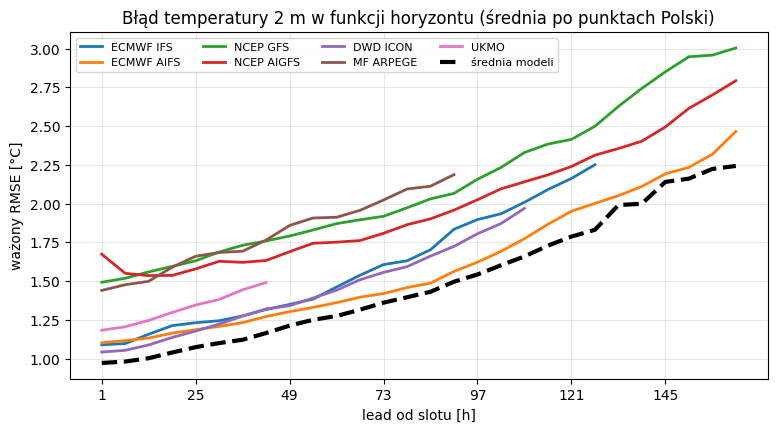

In [6]:
def weighted_rmse(fc, obs, w, min_coverage=MIN_COVERAGE):
    """Ważony RMSE [model, bucket, lat, lon]; NaN, gdy model ma za małe pokrycie bucketu.
    Liczymy model po modelu, żeby nie trzymać w pamięci błędów wszystkich modeli naraz."""
    w = xr.DataArray(np.asarray(w, np.float32), dims="slot")
    per_bucket = lambda x: x.coarsen(lead=BUCKET_H, coord_func="min").sum().sum("slot")
    num = xr.concat([per_bucket((f - obs) ** 2 * w) for f in fc], "model")
    den = xr.concat([per_bucket((f - obs).notnull() * w) for f in fc], "model")
    return np.sqrt(num / den).where(den >= min_coverage * den.max("model")).rename(lead="bucket")


def decay(end):
    """Waga slotu 0.5 ** (wiek / HALF_LIFE_D), wiek w dniach liczony od `end`."""
    return np.asarray(0.5 ** ((end - SLOTS) / pd.Timedelta(days=HALF_LIFE_D)))


def plot_rmse(rmse, fc, obs, models, ylabel, title):
    """RMSE modeli i średniej modeli w funkcji leadu, średnio po punktach Polski."""
    ens = weighted_rmse(fc.mean("model").expand_dims(model=["średnia modeli"]), obs, W)
    ax = xr.concat([rmse.assign_coords(model=list(models.values())), ens], "model") \
           .where(PL).mean(["lat", "lon"]).to_pandas().T.plot(figsize=(9, 4.5), lw=2)
    ax.lines[-1].set(color="k", lw=3, ls="--")
    ax.legend(ncol=4, fontsize=8)
    ax.set(xlabel="lead od slotu [h]", ylabel=ylabel, xticks=range(1, MAX_LEAD + 1, 24), title=title)
    ax.grid(alpha=0.3)


W = decay(SLOTS[-1])
RMSE = weighted_rmse(FC, OBS, W)
BEST = RMSE.fillna(np.inf).argmin("model")                        # indeks w MODELS dla (bucket, lat, lon)
print(f"ostatnie {HALF_LIFE_D} dni okna to {W[SLOTS > SLOTS[-1] - pd.Timedelta(days=HALF_LIFE_D)].sum() / W.sum():.0%} wagi")
plot_rmse(RMSE, FC, OBS, MODELS, "ważony RMSE [°C]", "Błąd temperatury 2 m w funkcji horyzontu (średnia po punktach Polski)")

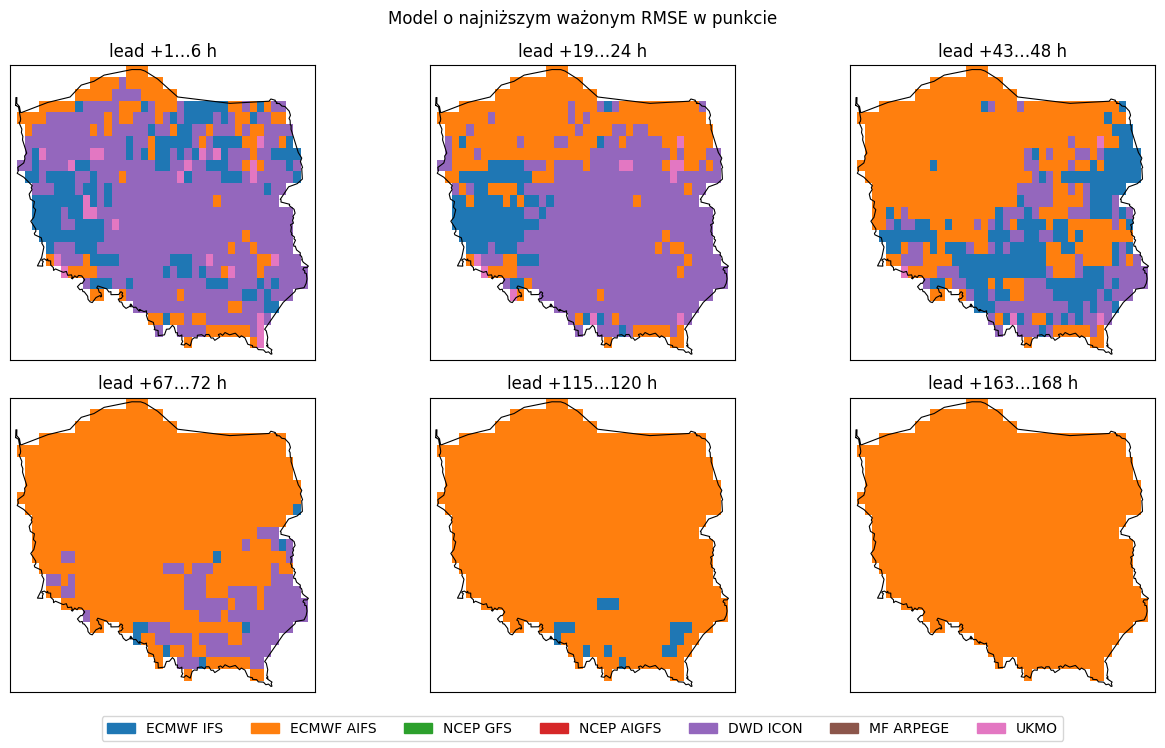

In [7]:
CMAP = mpl.colors.ListedColormap(plt.cm.tab10.colors[:len(MODELS)])
SHOW = [0, 3, 7, 11, 19, 27]                                      # buckety: +1, +19, +43, +67, +115, +163 h


def plot_maps(best, models, title):
    """Model o najniższym RMSE w każdym punkcie dla wybranych bucketów."""
    fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
    for ax, b in zip(axes.flat, SHOW):
        ax.pcolormesh(TLON, TLAT, best[b].where(PL), cmap=CMAP, vmin=-0.5, vmax=len(models) - 0.5)
        ax.plot(*RING.T, color="k", lw=0.8)
        lead0 = int(best.bucket[b])
        ax.set(title=f"lead +{lead0}…{lead0 + BUCKET_H - 1} h", xticks=[], yticks=[], aspect=1 / np.cos(np.radians(52)))
    fig.legend(handles=[mpl.patches.Patch(color=CMAP(i), label=l) for i, l in enumerate(models.values())],
               loc="lower center", ncol=len(models))
    fig.suptitle(title)
    plt.tight_layout(rect=(0, 0.05, 1, 1))


plot_maps(BEST, MODELS, "Model o najniższym ważonym RMSE w punkcie")

,ECMWF IFS,ECMWF AIFS,NCEP GFS,NCEP AIGFS,DWD ICON,MF ARPEGE,UKMO
bucket,,,,,,,
+1…6 h,20,15,0,0,62,0,3
+19…24 h,11,32,0,0,55,0,2
+43…48 h,24,58,0,0,17,0,1
+67…72 h,1,83,0,0,16,0,0
+115…120 h,3,97,0,0,0,0,0
+163…168 h,0,100,0,0,0,0,0


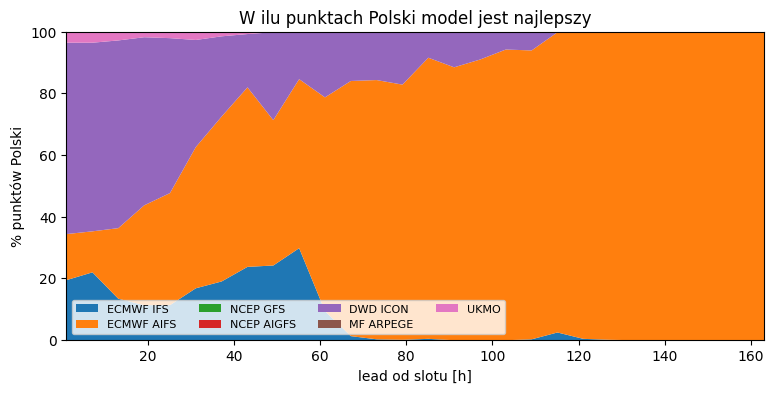

In [8]:
def plot_wins(best, models):
    """Udział punktów Polski, w których model jest najlepszy, w funkcji leadu -> tabela dla wybranych bucketów."""
    wins = pd.DataFrame({l: 100 * (best == i).where(PL).mean(["lat", "lon"]).to_series()
                         for i, l in enumerate(models.values())})
    ax = wins.plot.area(figsize=(9, 4), color=CMAP.colors, lw=0, xlim=(1, MAX_LEAD - BUCKET_H + 1), ylim=(0, 100),
                        xlabel="lead od slotu [h]", ylabel="% punktów Polski",
                        title="W ilu punktach Polski model jest najlepszy")
    ax.legend(ncol=4, fontsize=8, loc="lower left")
    return wins.iloc[SHOW].round().astype(int).rename(index=lambda b: f"+{b}…{b + BUCKET_H - 1} h")


plot_wins(BEST, MODELS)

---
## 7 · Czy mapa sprawdza się na nowych danych?

Mapa z sekcji 6 wskazuje model, który był najlepszy w przeszłości. Liczy się jednak, czy będzie
najlepszy także w przyszłości. Sprawdzamy to na danych, których mapa nie widziała:

1. **Podział okna.** Test to ostatnie `TEST_D` = 28 dni, a trening to wcześniejsza część okna.
   Między nimi zostawiamy 7 dni przerwy: prognoza z ostatniego dnia treningu sięga 7 dni do przodu,
   więc bez przerwy ta sama pogoda trafiłaby do obu części.
2. **Trening.** Liczymy RMSE i mapę dokładnie tak jak w sekcji 6, ale tylko z danych treningowych.
3. **Test.** Porównujemy zwykły RMSE (bez wag) trzech sposobów prognozowania:

| strategia | co serwujemy w danym punkcie |
|---|---|
| jeden model | wszędzie ten sam model: najlepszy na treningu średnio dla całej Polski |
| mapa | model wskazany przez mapę dla tego punktu i horyzontu |
| mieszanka modeli | średnia ważona wszystkich modeli z wagami z tego punktu i horyzontu |

W mieszance każdy model dostaje wagę `1 / RMSE²` z treningu, a wagi normalizujemy do sumy 1.
Przykład: jeśli w danym punkcie model A ma RMSE 1 °C, a model B 2 °C, to A dostaje wagę 1, a B 0.25,
czyli A wchodzi do mieszanki w 80%, a B w 20%.

Na koniec sprawdzamy, czy mapa jest stabilna, czyli w ilu parach (punkt, bucket) model wygrywający
na treningu wygrywa też na teście.

In [9]:
test = SLOTS >= SLOTS[-1] - pd.Timedelta(days=TEST_D)
train = SLOTS < SLOTS[test][0] - pd.Timedelta(hours=MAX_LEAD)         # 7 dni przerwy przed testem
w_tr = decay(SLOTS[train][-1]) * train                                 # wagi jak w sekcji 6, 0 poza treningiem


def to_lead(x):                                                       # [.., bucket, ..] -> [.., lead, ..]
    lead = xr.DataArray(np.arange(1, MAX_LEAD + 1), dims="lead")
    return x.isel(bucket=(lead - 1) // BUCKET_H).drop_vars("bucket").assign_coords(lead=lead.values)


def mixture(fc, rmse):
    """Mieszanka modeli dostępnych w danym slocie z wagami 1 / RMSE²."""
    w = (rmse ** -2).where(fc.notnull())
    return (fc * w).sum("model") / w.sum("model")


def strategies(fc_all, obs_all, models, w, suffix=""):
    """Prognozy trzech strategii na teście; ranking modeli i wagi mieszanki z treningu (wagi slotów `w`)."""
    rmse = weighted_rmse(fc_all, obs_all, w)
    one = rmse.where(PL).mean(["lat", "lon"]).mean("bucket", skipna=False).idxmin().item()  # tylko pełny horyzont
    fc = fc_all.isel(slot=test)
    return {f"jeden model ({models[one]}){suffix}": fc.sel(model=one),
            f"mapa{suffix}": fc.isel(model=to_lead(rmse.fillna(np.inf).argmin("model"))),
            # do wag bierzemy też modele z niepełnym pokryciem: w mieszance model liczy się tylko tam, gdzie ma prognozę
            f"mieszanka modeli{suffix}": mixture(fc, to_lead(weighted_rmse(fc_all, obs_all, w, min_coverage=0)))}


def score(strategies, obs_all):
    """RMSE na teście (punkty Polski): całość [strategia] i per bucket [bucket × strategia]."""
    obs = obs_all.isel(slot=test)
    se = {k: ((f - obs) ** 2).where(PL).reset_coords(drop=True) for k, f in strategies.items()}  # bez koordynaty "model" po wyborze
    return (pd.Series({k: float(np.sqrt(s.mean())) for k, s in se.items()}),
            pd.DataFrame({k: np.sqrt(s.coarsen(lead=BUCKET_H, coord_func="min").mean()
                                      .mean(["slot", "lat", "lon"])).to_series() for k, s in se.items()}))


def table(total, per_bucket, unit="°C"):
    tab = per_bucket.iloc[[0, 3, 11, 27]].T.rename(columns=lambda b: f"+{b}…{b + BUCKET_H - 1} h")
    tab.insert(0, f"RMSE [{unit}]", total)
    tab.insert(1, "zysk vs jeden model [%]", 100 * (1 - total / total.iloc[0]))
    return tab.round(3)


total, per_bucket = score(strategies(FC, OBS, MODELS, w_tr), OBS)
agree = (weighted_rmse(FC, OBS, test).fillna(np.inf).argmin("model")
         == weighted_rmse(FC, OBS, w_tr).fillna(np.inf).argmin("model")).where(PL).mean()
print(f"trening {SLOTS[train][0]:%Y-%m-%d} → {SLOTS[train][-1]:%Y-%m-%d} | "
      f"test {SLOTS[test][0]:%Y-%m-%d} → {SLOTS[test][-1]:%Y-%m-%d}")
print(f"stabilność mapy: zwycięzca z treningu wygrywa też na teście w {float(agree):.0%} par (punkt, bucket); "
      f"losowo ~{1 / len(MODELS):.0%}")
table(total, per_bucket)

trening 2026-05-22 → 2026-08-24 | test 2026-08-31 → 2026-09-28
stabilność mapy: zwycięzca z treningu wygrywa też na teście w 73% par (punkt, bucket); losowo ~14%


lead,RMSE [°C],zysk vs jeden model [%],+1…6 h,+19…24 h,+67…72 h,+163…168 h
jeden model (ECMWF AIFS),1.588,0.000,1.027,1.102,1.344,2.337
mapa,1.589,-0.096,0.981,1.052,1.371,2.337
mieszanka modeli,1.467,7.624,0.879,0.955,1.219,2.048


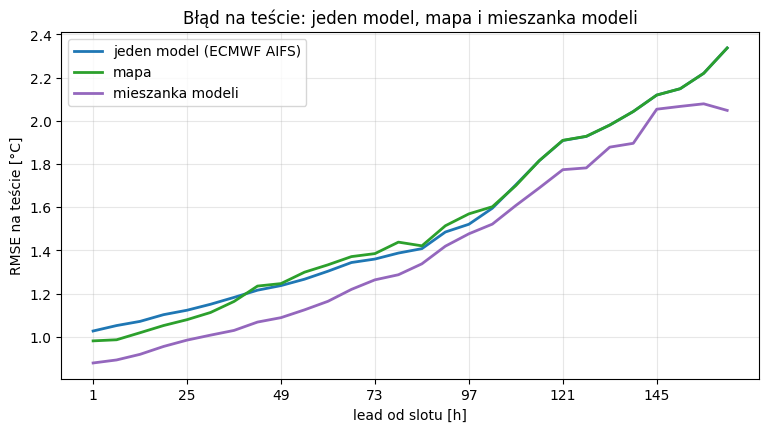

In [10]:
ax = per_bucket.plot(figsize=(9, 4.5), lw=2, color=["C0", "C2", "C4"], xlabel="lead od slotu [h]",
                     ylabel="RMSE na teście [°C]", xticks=range(1, MAX_LEAD + 1, 24),
                     title="Błąd na teście: jeden model, mapa i mieszanka modeli")
ax.grid(alpha=0.3);

---
## 8 · Korekta błędu systematycznego (walk-forward)

Model ma w danym miejscu powtarzalny błąd zależny od pory doby, np. zawyża temperaturę nocą
w dolinach albo zaniża ją w dzień nad morzem. Odjęcie tego błędu personalizuje prognozę w każdym
punkcie, osobno dla każdego modelu:

```
bias(model, godzina doby, punkt) = średni błąd prognoz, których czas ważności wpada w okno ERA5
prognoza po korekcie             = prognoza − bias(model, godzina doby czasu ważności, punkt)
```

**Test tak, jakbyśmy robili to w przeszłości.** Co `BIAS_REFRESH_D` = 7 dni podejmujemy decyzję D
i liczymy bias wyłącznie z danych dostępnych w chwili D:

* ERA5 jest aktualizowana raz na dobę z opóźnieniem `LAG` (z `meta.json`: moment publikacji minus
  koniec danych, ~5 dni). W chwili D znamy ją więc do `D − LAG`, zaokrąglonego w dół do pełnej doby,
* do biasu bierzemy **każdą** prognozę (dowolny slot i lead), której czas ważności wpada w ostatnie
  `BIAS_DAYS` dni tej ERA5,
* bias odejmujemy od prognoz ze slotów [D, D + 7 dni). Tych danych w chwili D jeszcze nie było.

Długość okna, horyzont, do którego korekta się opłaca, i częstość przeliczania dobieramy na okresie
**przed** testem z sekcji 7. Na teście mierzymy tylko wynik końcowy.

In [11]:
LAG = pd.Timedelta(seconds=ERA5_META["last_run_availability_time"] - ERA5_META["data_end_time"])
T0 = pd.Timestamp(ERA.time.values[0])
DECISIONS = pd.date_range((SLOTS[0] + LAG + pd.Timedelta(days=max(BIAS_WINDOWS) + 1)).ceil("D"), SLOTS[-1],
                          freq=f"{BIAS_REFRESH_D}D")


def error_sums(fc, obs):
    """Suma i liczba błędów po czasie ważności [model, godzina ERA5, lat, lon]: każda godzina zbiera błędy
    wszystkich slotów i leadów, które się wtedy weryfikują. Dla ustalonego leadu indeksy się nie powtarzają."""
    valid_ix = ((SLOTS - T0) // pd.Timedelta(hours=1)).to_numpy()[:, None] + fc.lead.values
    s = np.zeros((fc.sizes["model"], ERA.sizes["time"], len(TLAT), len(TLON)), np.float32)
    n = np.zeros_like(s)
    for l in range(MAX_LEAD):
        e = (fc[:, :, l] - obs[:, l]).values
        s[:, valid_ix[:, l]] += np.nan_to_num(e)
        n[:, valid_ix[:, l]] += np.isfinite(e)
    return s, n


def bias_at(sums, decision, days):
    """Bias [model, godzina doby, lat, lon] znany w chwili `decision`: ostatnie `days` dni dostępnej ERA5."""
    end = ((decision - LAG).floor("D") - T0) // pd.Timedelta(hours=1)
    s, n = (a[:, end - 24 * days:end].reshape(a.shape[0], days, 24, len(TLAT), len(TLON)).sum(1) for a in sums)
    return np.where(n > 0, s / np.maximum(n, 1), 0)


def walk_forward(fc, sums, days, refresh_d=BIAS_REFRESH_D, max_lead=MAX_LEAD):
    """Prognozy po korekcie: co `refresh_d` dni nowy bias, odejmowany od slotów do następnej decyzji
    na leadach <= max_lead (liczba albo wartość per model). Sloty przed pierwszą decyzją: NaN."""
    fcc = np.full(fc.shape, np.nan, np.float32)
    on = fc.lead.values[None, None, :, None, None] <= np.broadcast_to(max_lead, fc.sizes["model"])[:, None, None, None, None]
    for d in pd.date_range(DECISIONS[0], SLOTS[-1], freq=f"{refresh_d}D"):
        sel = np.flatnonzero((SLOTS >= d) & (SLOTS < d + pd.Timedelta(days=refresh_d)))
        hod = (SLOTS.hour.values[sel, None] + fc.lead.values) % 24      # godzina doby czasu ważności [slot, lead]
        fcc[:, sel] = fc.values[:, sel] - bias_at(sums, d, days)[:, hod] * on
    return fc.copy(data=fcc)


def gain(f, fc, obs, mask):
    """Zysk z korekty [model, dzień prognozy 1…7] w % RMSE prognoz `f` względem `fc` na slotach `mask`."""
    rmse = lambda x: np.sqrt(((x.isel(slot=mask) - obs.isel(slot=mask)) ** 2).where(PL)
                             .coarsen(lead=24).mean().mean(["slot", "lat", "lon"]))
    return (100 * (1 - rmse(f) / rmse(fc))).assign_coords(lead=np.arange(1, 8)).rename(lead="dzień")


SUMS = error_sums(FC, OBS)
tune = (SLOTS >= DECISIONS[0]) & ~test                              # strojenie: decyzje przed testem z sekcji 7
print(f"opóźnienie ERA5 {LAG} | decyzje co {BIAS_REFRESH_D} dni: {DECISIONS[0]:%Y-%m-%d} → {DECISIONS[-1]:%Y-%m-%d} "
      f"({len(DECISIONS)}) | strojenie na {tune.sum()} slotach, test na {test.sum()}")

opóźnienie ERA5 5 days 00:18:46 | decyzje co 7 dni: 2026-06-26 → 2026-09-25 (14) | strojenie na 267 slotach, test na 113


### Jak długie okno?

Krótkie okno szybko reaguje na zmianę pogody, ale z kilku dni nie da się odróżnić błędu systematycznego
od błędu konkretnej sytuacji pogodowej. Do tego przez opóźnienie ERA5 estymata ma już 5–12 dni, kiedy
ją stosujemy. Porównujemy okna z `BIAS_WINDOWS`: średni zysk po modelach na okresie strojenia,
w % RMSE, dla kolejnych dni prognozy.

In [12]:
GAINS = {w: gain(walk_forward(FC, SUMS, w), FC, OBS, tune) for w in BIAS_WINDOWS}
BIAS_DAYS = max(GAINS, key=lambda w: float(GAINS[w].mean()))
print(f"wybrane okno: {BIAS_DAYS} dni")
pd.DataFrame({f"okno {w} dni": g.mean("model").to_series().astype(float) for w, g in GAINS.items()}).T.add_prefix("dzień ").round(1)

wybrane okno: 28 dni


dzień,dzień 1,dzień 2,dzień 3,dzień 4,dzień 5,dzień 6,dzień 7
okno 3 dni,-5.6,-3.8,-2.7,-2.5,-3.0,-1.9,-1.0
okno 7 dni,2.5,3.0,3.0,3.0,2.4,2.1,1.7
okno 14 dni,8.2,7.3,6.6,6.1,4.4,3.5,2.7
okno 28 dni,12.5,10.7,9.4,8.1,5.2,4.0,3.5


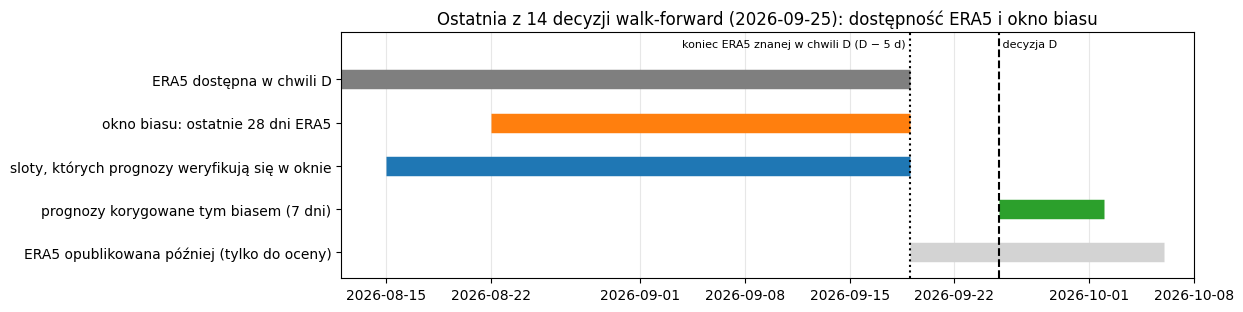

In [13]:
d, era_end = DECISIONS[-1], (DECISIONS[-1] - LAG).floor("D")
win0 = era_end - pd.Timedelta(days=BIAS_DAYS)
bars = [("ERA5 dostępna w chwili D", T0, era_end, "tab:gray"),
        (f"okno biasu: ostatnie {BIAS_DAYS} dni ERA5", win0, era_end, "tab:orange"),
        ("sloty, których prognozy weryfikują się w oknie", win0 - pd.Timedelta(hours=MAX_LEAD), era_end, "tab:blue"),
        (f"prognozy korygowane tym biasem ({BIAS_REFRESH_D} dni)", d, d + pd.Timedelta(days=BIAS_REFRESH_D), "tab:green"),
        ("ERA5 opublikowana później (tylko do oceny)", era_end, ERA5_END, "lightgray")]
fig, ax = plt.subplots(figsize=(11, 3.2))
for i, (_, a, b, color) in enumerate(bars):
    ax.hlines(i, a, b, color=color, lw=14)
ax.axvline(d, color="k", ls="--")
ax.axvline(era_end, color="k", ls=":")
ax.text(d, -0.75, " decyzja D", fontsize=8)
ax.text(era_end, -0.75, f"koniec ERA5 znanej w chwili D (D − {LAG.days} d) ", fontsize=8, ha="right")
ax.set(yticks=range(len(bars)), yticklabels=[b[0] for b in bars], ylim=(len(bars) - 0.4, -1.1),
       xlim=(win0 - pd.Timedelta(days=10), ERA5_END + pd.Timedelta(days=2)),
       title=f"Ostatnia z {len(DECISIONS)} decyzji walk-forward ({d:%Y-%m-%d}): dostępność ERA5 i okno biasu")
ax.grid(axis="x", alpha=0.3);

### Do jakiego horyzontu i jak często przeliczać?

Dla wybranego okna sprawdzamy zysk osobno dla każdego modelu i dnia prognozy. Korektę stosujemy
od początku horyzontu do ostatniego dnia, w którym jeszcze pomaga (`BIAS_MAX_LEAD`, osobno dla
każdego modelu). Dwa dodatkowe pytania: czy bias liczony raz na tydzień traci wartość w ciągu
tygodnia i czy codzienne przeliczanie coś daje.

średni zysk po modelach i dniach: przeliczanie co 7 dni 7.9%, codziennie 7.8%
zysk vs dni od decyzji [%]: {0: 8.3, 1: 8.2, 2: 8.0, 3: 7.1, 4: 7.4, 5: 7.8, 6: 7.9}


,dzień 1,dzień 2,dzień 3,dzień 4,dzień 5,dzień 6,dzień 7,korekta do leadu [h]
ECMWF IFS,7.3,5.9,5.3,4.4,3.4,3.3,4.1,168
ECMWF AIFS,18.0,16.3,14.8,11.5,8.0,5.8,5.2,168
NCEP GFS,6.2,3.1,2.2,2.0,1.0,-0.4,-1.2,120
NCEP AIGFS,22.1,20.6,17.4,14.7,12.3,9.7,7.6,168
DWD ICON,5.8,4.4,3.6,3.0,2.5,1.9,1.5,168
MF ARPEGE,16.3,16.1,15.3,16.3,NaN,NaN,NaN,96
UKMO,11.4,8.4,7.2,5.0,4.0,3.5,3.9,168


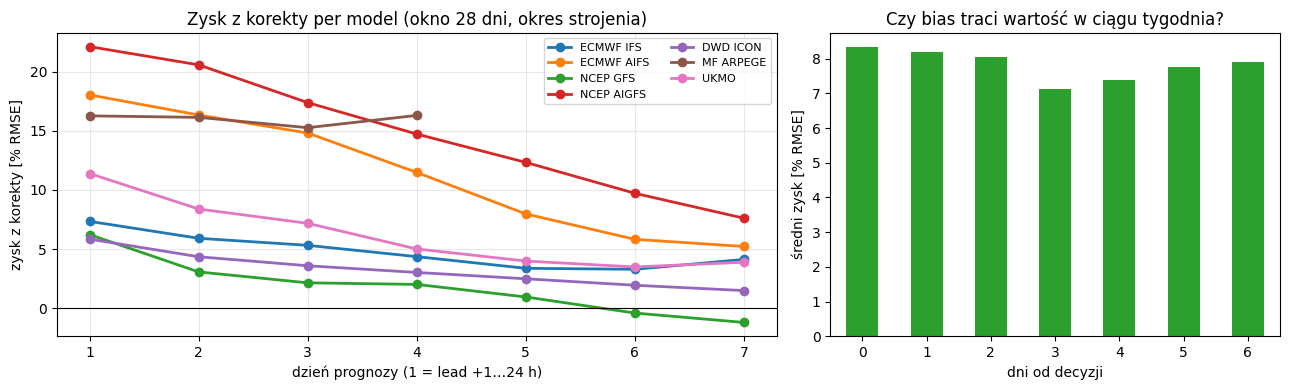

In [14]:
g = GAINS[BIAS_DAYS]
BIAS_MAX_LEAD = 24 * (g > 0).cumprod("dzień").sum("dzień")          # [model] w h; 0 = bez korekty
FCC = walk_forward(FC, SUMS, BIAS_DAYS, max_lead=BIAS_MAX_LEAD.values)

days_since = ((SLOTS - DECISIONS[0]) % pd.Timedelta(days=BIAS_REFRESH_D)).days   # dni od ostatniej decyzji
by_age = pd.Series({a: float(gain(FCC, FC, OBS, tune & (days_since == a)).mean()) for a in range(BIAS_REFRESH_D)})
daily = float(gain(walk_forward(FC, SUMS, BIAS_DAYS, refresh_d=1, max_lead=BIAS_MAX_LEAD.values), FC, OBS, tune).mean())
print(f"średni zysk po modelach i dniach: przeliczanie co {BIAS_REFRESH_D} dni "
      f"{float(gain(FCC, FC, OBS, tune).mean()):.1f}%, codziennie {daily:.1f}%")
print("zysk vs dni od decyzji [%]:", by_age.round(1).to_dict())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.6, 1]})
g.assign_coords(model=list(MODELS.values())).to_pandas().T.plot(ax=ax1, marker="o", lw=2)
ax1.axhline(0, color="k", lw=0.8)
ax1.set(xlabel="dzień prognozy (1 = lead +1…24 h)", ylabel="zysk z korekty [% RMSE]",
        title=f"Zysk z korekty per model (okno {BIAS_DAYS} dni, okres strojenia)")
ax1.legend(ncol=2, fontsize=8)
ax1.grid(alpha=0.3)
by_age.plot.bar(ax=ax2, color="tab:green", rot=0, xlabel="dni od decyzji", ylabel="średni zysk [% RMSE]",
                title="Czy bias traci wartość w ciągu tygodnia?")
plt.tight_layout()
pd.DataFrame(g.values.astype(float), index=list(MODELS.values()), columns=[f"dzień {i}" for i in g["dzień"].values]) \
  .round(1).assign(**{"korekta do leadu [h]": BIAS_MAX_LEAD.values})

### Wynik na teście

Na teście z sekcji 7 porównujemy strategie bez korekty i z korektą. Przy korekcie ranking modeli
i wagi liczymy z prognoz już skorygowanych (trening od pierwszej decyzji), bo po odjęciu biasu
modele zmieniają kolejność.

lead,RMSE [°C],zysk vs jeden model [%],+1…6 h,+19…24 h,+67…72 h,+163…168 h
jeden model (ECMWF AIFS),1.588,0.000,1.027,1.102,1.344,2.337
mapa,1.589,-0.096,0.981,1.052,1.371,2.337
mieszanka modeli,1.467,7.624,0.879,0.955,1.219,2.048
jeden model (ECMWF AIFS) + korekta,1.466,7.708,0.952,0.986,1.208,2.205
mapa + korekta,1.467,7.631,0.958,0.988,1.208,2.205
mieszanka modeli + korekta,1.401,11.766,0.855,0.929,1.190,1.958


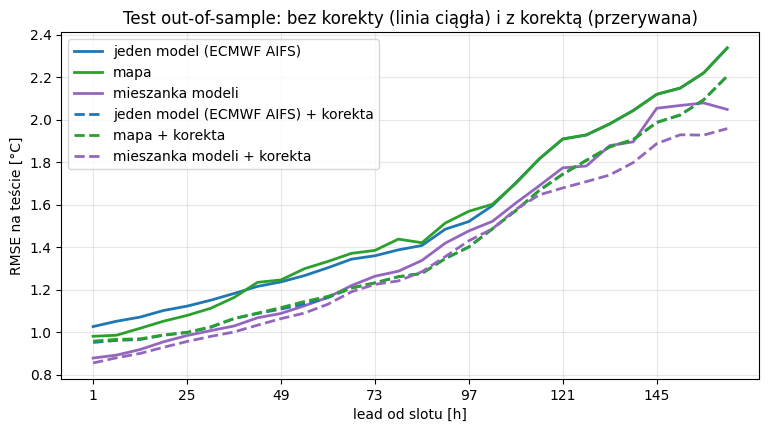

In [15]:
w_c = w_tr * (SLOTS >= DECISIONS[0])                                 # trening tylko ze slotów z korektą
total_c, per_bucket_c = score(strategies(FCC, OBS, MODELS, w_c, " + korekta"), OBS)
ax = pd.concat([per_bucket, per_bucket_c], axis=1).plot(
    figsize=(9, 4.5), lw=2, color=["C0", "C2", "C4"] * 2, style=["-"] * 3 + ["--"] * 3,
    xlabel="lead od slotu [h]", ylabel="RMSE na teście [°C]", xticks=range(1, MAX_LEAD + 1, 24),
    title="Test out-of-sample: bez korekty (linia ciągła) i z korektą (przerywana)")
ax.grid(alpha=0.3)
table(pd.concat([total, total_c]), pd.concat([per_bucket, per_bucket_c], axis=1))

---
## 9 · Zapis mapy modeli

`model_map_temperature_2m.zarr` (i analogicznie plik dla ciśnienia w sekcji 10) zawiera:

* `best_model[bucket, lat, lon]`: indeks modelu na liście `attrs["models"]` (z progiem pokrycia
  z sekcji 6). To odpowiedź na pytanie „jaki model jest najlepszy w mojej miejscowości”,
* `rmse[model, bucket, lat, lon]`: ważony RMSE modeli bez korekty, bez progu pokrycia (NaN tylko poza
  zasięgiem modelu). Daje ranking i kolejność zapasowych modeli, gdy najlepszemu brakuje runu,
* `rmse_corrected[model, bucket, lat, lon]`: to samo po korekcie. Z niego liczy się wagi
  `1 / rmse_corrected²` mieszanki modeli, którą serwujemy,
* `bias[model, hour, lat, lon]` i `bias_max_lead[model]`: najświeższy bias z okna `attrs["bias_window"]`.
  Prognozę koryguje się jako `prognoza − bias[model, godzina doby czasu ważności, punkt]`, ale tylko
  dla leadów ≤ `bias_max_lead[model]`. Ten bias pochodzi z danych notebooka, więc jest o kilkanaście
  dni starszy od „dziś” (ostatni slot musi mieć 7 dni weryfikacji). Zadanie cykliczne w produkcji
  będzie go liczyć co tydzień z najnowszej ERA5,
* `in_poland[lat, lon]`: maska punktów w granicach Polski.

Nazwy modeli trzymamy w atrybucie, a nie jako koordynatę tekstową, bo tekst nie ma jeszcze
specyfikacji w Zarr v3 i inne biblioteki mogłyby go nie odczytać.

`bucket` to pierwsza godzina bucketu lead (1, 7, …, 163). Lead jest liczony **od slotu
odświeżenia** (00/06/12/18 UTC), a nie od inicjalizacji runu.

In [16]:
def save_model_map(variable, models, fc, obs, fcc, sums, bias_days, bias_max_lead):
    """Wyniki jednej zmiennej -> model_map_{variable}.zarr."""
    bias_end = (SLOTS[-1].floor("D") - LAG).floor("D")
    ds = xr.Dataset(
        {"best_model": weighted_rmse(fc, obs, W).fillna(np.inf).argmin("model").astype("int8"), "in_poland": PL,
         "rmse": weighted_rmse(fc, obs, W, min_coverage=0).astype("float32"),
         "rmse_corrected": weighted_rmse(fcc, obs, W * (SLOTS >= DECISIONS[0]), min_coverage=0).astype("float32"),
         "bias": (("model", "hour", "lat", "lon"), bias_at(sums, SLOTS[-1].floor("D"), bias_days).astype("float32")),
         "bias_max_lead": bias_max_lead.astype("int16")},
        coords={"hour": np.arange(24)},
        attrs={"models": list(models), "variable": variable, "bucket_h": BUCKET_H,
               "half_life_days": HALF_LIFE_D, "slots": f"{SLOTS[0]} – {SLOTS[-1]}", "bias_days": bias_days,
               "bias_window": f"{bias_end - pd.Timedelta(days=bias_days)} – {bias_end}"}).drop_vars("model")
    ds.to_zarr(CACHE / f"model_map_{variable}.zarr", mode="w", consolidated=False)
    return ds


save_model_map("temperature_2m", MODELS, FC, OBS, FCC, SUMS, BIAS_DAYS, BIAS_MAX_LEAD)

<xarray.Dataset> Size: 2MB
Dimensions:         (bucket: 28, lat: 25, lon: 42, model: 7, hour: 24)
Coordinates:
  * bucket          (bucket) int64 224B 1 7 13 19 25 31 ... 139 145 151 157 163
  * lat             (lat) float64 200B 49.0 49.25 49.5 49.75 ... 54.5 54.75 55.0
  * lon             (lon) float64 336B 14.0 14.25 14.5 ... 23.75 24.0 24.25
  * hour            (hour) int64 192B 0 1 2 3 4 5 6 7 ... 17 18 19 20 21 22 23
Dimensions without coordinates: model
Data variables:
    best_model      (bucket, lat, lon) int8 29kB 4 1 4 6 4 4 4 ... 1 1 1 1 1 1 1
    in_poland       (lat, lon) bool 1kB False False False ... False False False
    rmse            (model, bucket, lat, lon) float32 823kB 1.356 1.402 ... nan
    rmse_corrected  (model, bucket, lat, lon) float32 823kB 1.199 1.294 ... nan
    bias            (model, hour, lat, lon) float32 706kB 0.1432 ... 0.2277
    bias_max_lead   (model) int16 14B 168 168 120 168 168 96 168
Attributes:
    models:          ['ecmwf_ifs025', 'ecmwf_aifs025_single', 'ncep_gfs013', ...
    variable:        temperature_2m
    bucket_h:        6
    half_life_days:  21
    slots:           2026-05-22 18:00:00 – 2026-09-28 18:00:00
    bias_days:       28
    bias_window:     2026-08-25 00:00:00 – 2026-09-22 00:00:00

---
## 10 · Ciśnienie

Ten sam backtest dla ciśnienia zredukowanego do poziomu morza (`pressure_msl`, hPa). Metody są takie
same jak dla temperatury, więc pokazujemy tylko wyniki. Różnice:

* GFS bierzemy z `ncep_gfs025` (siatka 0.25°, krok 1 h do +120 h, dalej 3 h), bo `ncep_gfs013` nie ma
  ciśnienia,
* ERA5 zapisuje ciśnienie w Pa, a modele w hPa, więc ERA5 dzielimy przez 100,
* runy ciśnienia mamy tylko z ostatnich ~94 dni, bo wcześniej tej zmiennej nie pobieraliśmy, a starszych
  runów bucket S3 już nie ma. Sloty bez prognoz są pomijane, więc trening jest krótszy niż dla temperatury.

Wyniki temperatury są już zapisane, więc zwalniamy jej tablice z pamięci.

pressure_msl: do pobrania 1355 runów


{'ECMWF IFS': 329, 'ECMWF AIFS': 328, 'NCEP GFS': 329, 'NCEP AIGFS': 328, 'DWD ICON': 328, 'MF ARPEGE': 324, 'UKMO': 326}


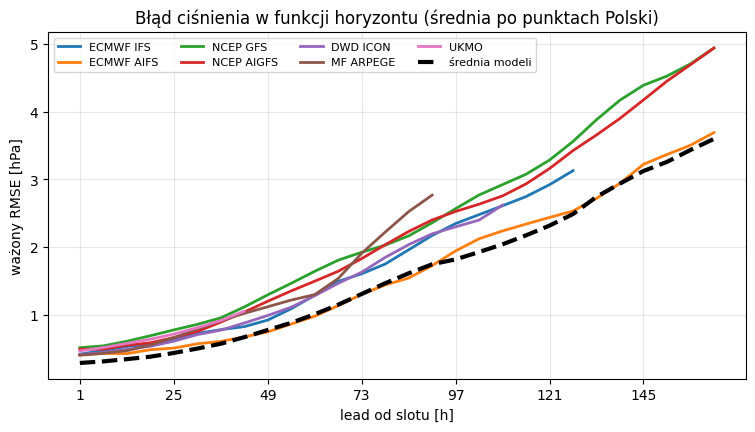

In [17]:
del FC, OBS, FCC, SUMS                                                 # temperatura zapisana: zwalniamy ~8 GB RAM
MODELS_P = {("ncep_gfs025" if m == "ncep_gfs013" else m): l for m, l in MODELS.items()}
ERA_P = download_era5("pressure_msl") / 100                            # Pa -> hPa
print(download_runs(MODELS_P, "pressure_msl").to_dict())
FC_P, OBS_P, _, _ = forecasts(MODELS_P, "pressure_msl", ERA_P)
RMSE_P = weighted_rmse(FC_P, OBS_P, W)
BEST_P = RMSE_P.fillna(np.inf).argmin("model")
plot_rmse(RMSE_P, FC_P, OBS_P, MODELS_P, "ważony RMSE [hPa]", "Błąd ciśnienia w funkcji horyzontu (średnia po punktach Polski)")

,ECMWF IFS,ECMWF AIFS,NCEP GFS,NCEP AIGFS,DWD ICON,MF ARPEGE,UKMO
bucket,,,,,,,
+1…6 h,15,13,0,0,26,42,4
+19…24 h,0,71,0,0,26,3,0
+43…48 h,0,100,0,0,0,0,0
+67…72 h,0,100,0,0,0,0,0
+115…120 h,0,100,0,0,0,0,0
+163…168 h,0,100,0,0,0,0,0


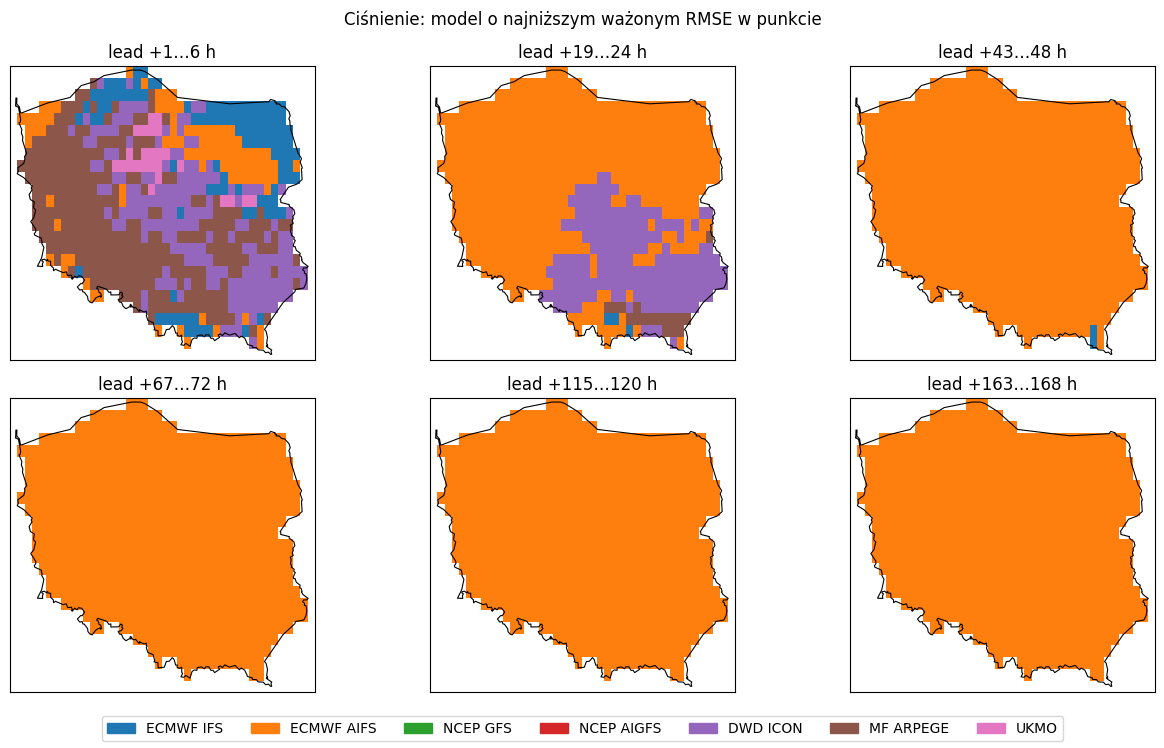

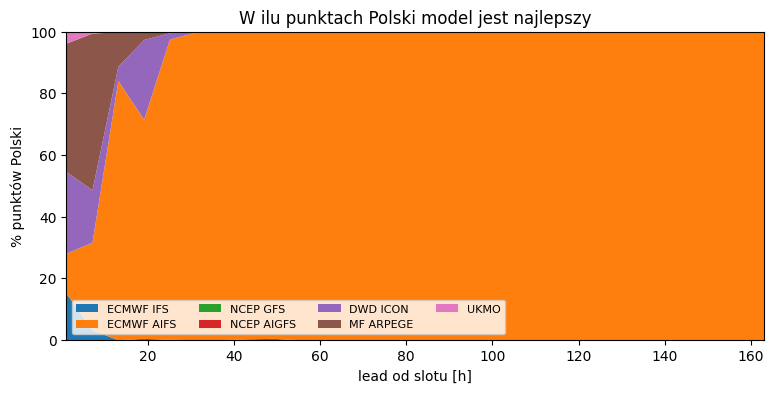

In [18]:
plot_maps(BEST_P, MODELS_P, "Ciśnienie: model o najniższym ważonym RMSE w punkcie")
plot_wins(BEST_P, MODELS_P)

Korekta błędu systematycznego (jak w sekcji 8) i test na nowych danych (jak w sekcji 7). Korektę
stosujemy tylko do tych leadów, na których pomaga na okresie strojenia; jeśli nigdzie nie pomaga,
`MAX_LEAD_P` wynosi 0 i ciśnienie serwujemy bez korekty.

In [19]:
SUMS_P = error_sums(FC_P, OBS_P)
GAINS_P = {w: gain(walk_forward(FC_P, SUMS_P, w), FC_P, OBS_P, tune) for w in BIAS_WINDOWS}
BIAS_DAYS_P = max(GAINS_P, key=lambda w: float(GAINS_P[w].mean()))
MAX_LEAD_P = 24 * (GAINS_P[BIAS_DAYS_P] > 0).cumprod("dzień").sum("dzień")
print(f"wybrane okno: {BIAS_DAYS_P} dni | korekta do leadu [h]:", dict(zip(MODELS_P.values(), MAX_LEAD_P.values.tolist())))
pd.DataFrame({f"okno {w} dni": g.mean("model").to_series().astype(float) for w, g in GAINS_P.items()}).T.add_prefix("dzień ").round(1)

wybrane okno: 28 dni | korekta do leadu [h]: {'ECMWF IFS': 0, 'ECMWF AIFS': 0, 'NCEP GFS': 0, 'NCEP AIGFS': 0, 'DWD ICON': 0, 'MF ARPEGE': 0, 'UKMO': 0}


dzień,dzień 1,dzień 2,dzień 3,dzień 4,dzień 5,dzień 6,dzień 7
okno 3 dni,-47.0,-22.0,-10.4,-7.5,-3.6,-1.3,0.2
okno 7 dni,-36.0,-16.9,-8.4,-6.3,-2.5,-0.5,0.5
okno 14 dni,-17.8,-6.8,-2.3,-1.7,-0.5,0.1,0.1
okno 28 dni,-12.7,-4.3,-0.9,-0.9,-0.4,-0.4,-0.4


In [20]:
FCC_P = walk_forward(FC_P, SUMS_P, BIAS_DAYS_P, max_lead=MAX_LEAD_P.values)
agree_p = (weighted_rmse(FC_P, OBS_P, test).fillna(np.inf).argmin("model")
           == weighted_rmse(FC_P, OBS_P, w_tr).fillna(np.inf).argmin("model")).where(PL).mean()
print(f"stabilność mapy: zwycięzca z treningu wygrywa też na teście w {float(agree_p):.0%} par (punkt, bucket)")
table(*score(strategies(FC_P, OBS_P, MODELS_P, w_tr), OBS_P), "hPa")

stabilność mapy: zwycięzca z treningu wygrywa też na teście w 88% par (punkt, bucket)


lead,RMSE [hPa],zysk vs jeden model [%],+1…6 h,+19…24 h,+67…72 h,+163…168 h
jeden model (ECMWF AIFS),2.025,0.000,0.415,0.466,1.131,3.745
mapa,2.031,-0.278,0.405,0.465,1.131,3.745
mieszanka modeli,1.849,8.685,0.280,0.356,1.059,3.477


In [21]:
save_model_map("pressure_msl", MODELS_P, FC_P, OBS_P, FCC_P, SUMS_P, BIAS_DAYS_P, MAX_LEAD_P)

<xarray.Dataset> Size: 2MB
Dimensions:         (bucket: 28, lat: 25, lon: 42, model: 7, hour: 24)
Coordinates:
  * bucket          (bucket) int64 224B 1 7 13 19 25 31 ... 139 145 151 157 163
  * lat             (lat) float64 200B 49.0 49.25 49.5 49.75 ... 54.5 54.75 55.0
  * lon             (lon) float64 336B 14.0 14.25 14.5 ... 23.75 24.0 24.25
  * hour            (hour) int64 192B 0 1 2 3 4 5 6 7 ... 17 18 19 20 21 22 23
Dimensions without coordinates: model
Data variables:
    best_model      (bucket, lat, lon) int8 29kB 1 5 5 5 5 1 5 ... 1 1 1 1 1 1 1
    in_poland       (lat, lon) bool 1kB False False False ... False False False
    rmse            (model, bucket, lat, lon) float32 823kB 0.5062 ... nan
    rmse_corrected  (model, bucket, lat, lon) float32 823kB 0.5062 ... nan
    bias            (model, hour, lat, lon) float32 706kB -0.5027 ... -0.4008
    bias_max_lead   (model) int16 14B 0 0 0 0 0 0 0
Attributes:
    models:          ['ecmwf_ifs025', 'ecmwf_aifs025_single', 'ncep_gfs025', ...
    variable:        pressure_msl
    bucket_h:        6
    half_life_days:  21
    slots:           2026-05-22 18:00:00 – 2026-09-28 18:00:00
    bias_days:       28
    bias_window:     2026-08-25 00:00:00 – 2026-09-22 00:00:00

---
## 11 · Wnioski

Okno: sloty 2026-05-22 → 2026-09-28 (517 slotów, 3596 runów 7 modeli). Strojenie korekty: decyzje
2026-06-26 → 2026-08-28. Test out-of-sample: 2026-08-31 → 2026-09-28. Liczby pochodzą z tego
uruchomienia i po przesunięciu okna się zmienią.

**Infrastruktura**

1. **Dane są darmowe i nie trzeba pobierać całych siatek.** Wycinek Polski z jednego runu to
   1.5–2.5 MB zamiast całego pliku (546 MB dla GFS).
2. **Bucket S3 trzyma runy tylko ~94 dni.** Okno ma 130 dni wyłącznie dzięki runom zachowanym
   z wcześniejszego pobrania. Historii nie da się odtworzyć wstecz, więc automatyczne pobieranie
   powinno ruszyć jak najszybciej i odkładać runy do `runs/`.
3. **Lead trzeba liczyć od slotu.** IFS i UKMO publikują się z opóźnieniem ponad 6 h (7.7 h i 7.2 h),
   więc w serwisie ich run ma zawsze 12 h, a nie 6 h. ERA5 ma opóźnienie 5 dni, co ogranicza korektę.

**Który model jest najlepszy w mojej miejscowości**

4. **Na pierwszą dobę najlepszy jest DWD ICON, dalej ECMWF AIFS.** ICON ma najniższy RMSE średnio
   po Polsce do +30 h i wygrywa w 50–62% punktów; ECMWF IFS wygrywa wtedy głównie na zachodzie kraju.
   Od +31 h prowadzi AIFS: od +37 h wygrywa w większości punktów, a od +121 h we wszystkich.
   NCEP GFS, NCEP AIGFS i MF ARPEGE nie wygrywają nigdzie.
5. **Mapa jest stabilna.** Zwycięzca z treningu wygrywa też na teście w 73% par (punkt, bucket),
   przy ~14% dla wyboru losowego. Obszary zwycięstw są geograficznie spójne.
6. **Sam wybór modelu poprawia prognozę tylko na pierwszą dobę.** Na +1…24 h mapa jest o ~4.5%
   lepsza od AIFS wszędzie, ale na +43…72 h o 1.5–2% gorsza, a od ~+96 h to po prostu AIFS.
   Mieszanka modeli z wagami tego punktu (`1 / RMSE²`) jest lepsza od każdego wyboru jednego modelu.

**Korekta błędu systematycznego (sekcja 8)**

7. **Okno musi mieć ~4 tygodnie.** Z 3 dni ERA5 korekta szkodzi (−5.6% na pierwszą dobę): krótkie
   okno łapie pogodę, a nie błąd modelu, a przez 5-dniowe opóźnienie ERA5 jest już nieaktualne, gdy
   je stosujemy. Z 28 dni korekta daje +12.5% na pierwszą dobę i +3.5% na siódmą.
8. **Pomaga każdemu modelowi, najbardziej modelom AI.** Na pierwszą dobę AIGFS zyskuje 22%, AIFS
   18%, ARPEGE 16%, UKMO 11%, a IFS, GFS i ICON 6–7%, bo mają mały błąd systematyczny. GFS od
   6. dnia już traci, więc korygujemy go do +120 h; pozostałe modele na całym swoim horyzoncie.
9. **Wystarczy przeliczać raz w tygodniu.** Zysk nie spada w ciągu tygodnia (8.3% w dniu decyzji,
   7.9% po 6 dniach), a codzienne przeliczanie daje tyle samo (7.8% wobec 7.9%).
10. **Wynik końcowy na teście:**

    | strategia | RMSE | zysk vs AIFS | +1…6 h | +19…24 h | +67…72 h | +163…168 h |
    |---|---|---|---|---|---|---|
    | jeden model (AIFS wszędzie) | 1.588 °C | — | 1.027 | 1.102 | 1.344 | 2.337 |
    | mapa | 1.589 °C | −0.1% | 0.981 | 1.052 | 1.371 | 2.337 |
    | mieszanka modeli | 1.467 °C | +7.6% | 0.879 | 0.955 | 1.219 | 2.048 |
    | jeden model (AIFS) + korekta | 1.466 °C | +7.7% | 0.952 | 0.986 | 1.208 | 2.205 |
    | mapa + korekta | 1.467 °C | +7.6% | 0.958 | 0.988 | 1.208 | 2.205 |
    | **mieszanka modeli + korekta** | **1.401 °C** | **+11.8%** | 0.855 | 0.929 | 1.190 | 1.958 |

    Korekta i mieszanka modeli się sumują: personalizacja przez wagi i bias danego punktu daje
    +11.8% względem najlepszego modelu użytego w całej Polsce, a na pierwsze 6 h +17%.

**Ciśnienie (sekcja 10)**

11. **Na pierwszą dobę wygrywają różne modele, dalej wszędzie ECMWF AIFS.** Na +1…6 h najczęściej
    wygrywa MF ARPEGE (42% punktów), potem DWD ICON i ECMWF IFS. Od +43 h AIFS jest najlepszy
    w każdym punkcie. Mapa jest stabilna (88% zgodności trening/test), ale to głównie dlatego,
    że prawie wszędzie wskazuje ten sam model.
12. **Wybór modelu w punkcie nic nie daje, mieszanka tak.** Na teście: AIFS wszędzie 2.025 hPa,
    mapa 2.031 hPa (−0.3%), mieszanka modeli 1.849 hPa (+8.7%). Ciśnienie to pole wielkoskalowe,
    więc lokalne różnice między modelami są małe.
13. **Korekta błędu systematycznego szkodzi przy każdym oknie** (na pierwszą dobę od −13% przy
    28 dniach do −47% przy 3 dniach), więc jej nie stosujemy. Bias liczony ze wszystkich leadów
    jest zdominowany przez duże, losowe błędy prognoz na kilka dni do przodu, a ciśnienie nie ma
    lokalnego błędu systematycznego (jak temperatura w dolinach czy nad morzem), który by to równoważył.

**Rekomendacja dla serwisu.** W każdym punkcie serwujemy mieszankę modeli z wagami tego punktu
i horyzontu (`1 / rmse_corrected²`). Dla temperatury przedtem odejmujemy bias każdego modelu
(`bias`, przeliczany co tydzień z ostatnich 28 dni ERA5, do `bias_max_lead`), a dla ciśnienia nie.
Na pytanie „jaki model jest najlepszy w mojej miejscowości” odpowiada `best_model` z rankingiem z `rmse`.

**Ograniczenia**

* ERA5 jako prawda faworyzuje modele ECMWF: AIFS był trenowany na ERA5, a IFS to ten sam system,
  na którym oparta jest asymilacja ERA5. Mapa mówi więc „najbliżej ERA5”, a nie „najbliżej
  pomiaru”.
* Modele o wyższej rozdzielczości (GFS 0.117°, UKMO 10 km) porównujemy w najbliższym węźle
  z reanalizą 0.25°. Drobnoskalowe szczegóły, które oddają, ERA5 liczy jako błąd.
* Okno to maj–wrzesień. Zimą ranking i bias mogą wyglądać inaczej, więc oba trzeba przeliczać cyklicznie.